# CareFlow Hospital Operations — Python EDA & Visualizations

## Objective
Explore the synthetic CareFlow hospital event log using beginner-friendly Python and pandas. This notebook covers data loading, data quality, cleaning, KPIs, activity patterns, patient sequences, repeated activities, transition times, visualizations, business insights, and CSV exports.


## 1. Import libraries

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the dataset

In [42]:
df_raw = pd.read_csv("careflow_raw_event_log.csv")
df = df_raw.copy()

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())


Dataset loaded successfully!
Rows and columns: (6443, 9)


,Case_ID,Activity_Name,Timestamp,Patient_Age,Gender,Department,Doctor_ID,Pathway_Type,Event_Reason
0,P0001,registration,2026-09-03 16:21:00,70,Male,Emergency,D02,Normal,NaN
1,P0001,Triage,2026-09-03 16:29:00,70,Male,Emergency,D02,Normal,NaN
2,P0001,Doctor,2026-09-03 16:57:00,70,Male,Emergency,D02,Normal,NaN
3,P0001,X-RAY,2026-09-03 17:16:00,70,Male,Emergency,D02,Normal,NaN
4,P0001,Treatment,2026-09-03 18:07:00,70,Male,Emergency,D02,Normal,NaN


## 3. Understand the dataset

In [43]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Column names:
['Case_ID', 'Activity_Name', 'Timestamp', 'Patient_Age', 'Gender', 'Department', 'Doctor_ID', 'Pathway_Type', 'Event_Reason']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6443 entries, 0 to 6442
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Case_ID        6443 non-null   object
 1   Activity_Name  6443 non-null   object
 2   Timestamp      6443 non-null   object
 3   Patient_Age    6443 non-null   int64 
 4   Gender         6443 non-null   object
 5   Department     6443 non-null   object
 6   Doctor_ID      6443 non-null   object
 7   Pathway_Type   6443 non-null   object
 8   Event_Reason   436 non-null    object
dtypes: int64(1), object(8)
memory usage: 453.2+ KB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Case_ID,6443,1000,P0037,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Activity_Name,6443,6,Doctor,1242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Timestamp,6443,5956,2026-09-04 05:36:00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Patient_Age,6443.0,NaN,NaN,NaN,51.122303,19.36316,18.0,34.0,50.0,68.0,85.0
Gender,6443,3,Female,3308,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,6443,2,Emergency,5786,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Doctor_ID,6443,15,D08,656,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pathway_Type,6443,5,Normal,4566,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Event_Reason,436,7,Clinical re-check,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Check required columns

In [44]:
df.columns = [str(col).strip().replace(" ", "_") for col in df.columns]

rename_map = {
    "case_id": "Case_ID",
    "CaseID": "Case_ID",
    "activity_name": "Activity_Name",
    "Activity": "Activity_Name",
    "timestamp": "Timestamp",
    "DateTime": "Timestamp"
}
df = df.rename(columns={old: new for old, new in rename_map.items() if old in df.columns})

required_columns = ["Case_ID", "Activity_Name", "Timestamp"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}. Available: {df.columns.tolist()}")

print("Required columns are available.")


Required columns are available.


## 5. Data quality: missing values and duplicates

,Missing_Count,Missing_Percent
Event_Reason,6007,93.23
Case_ID,0,0.00
Activity_Name,0,0.00
Patient_Age,0,0.00
Timestamp,0,0.00
Gender,0,0.00
Department,0,0.00
Doctor_ID,0,0.00
Pathway_Type,0,0.00


Exact duplicate rows: 8


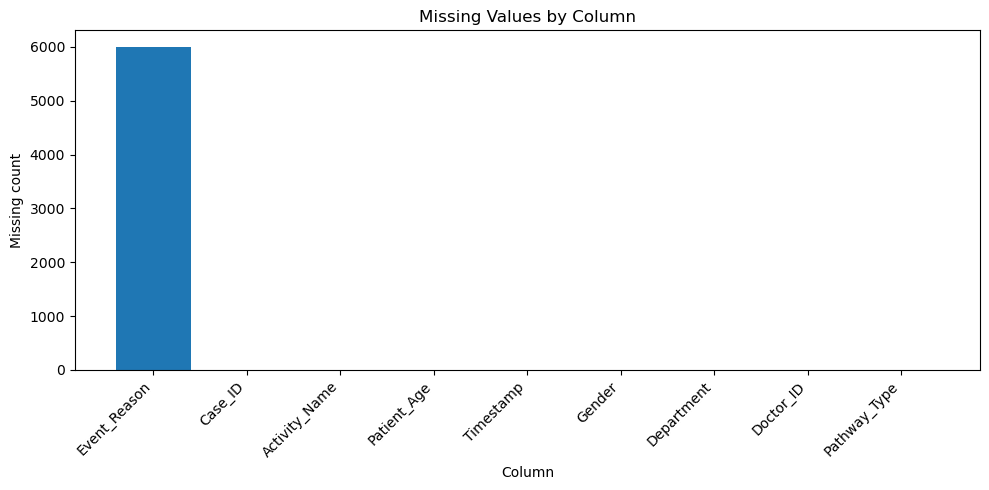

In [45]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

display(missing_summary)
print("Exact duplicate rows:", int(df.duplicated().sum()))

plt.figure(figsize=(10, 5))
plt.bar(missing_summary.index.astype(str), missing_summary["Missing_Count"])
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 6. Clean the dataset

In [46]:
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

rows_before = len(df)
df = df.dropna(subset=["Case_ID", "Activity_Name", "Timestamp"])
rows_after_required = len(df)
df = df.drop_duplicates()
rows_after = len(df)

df["Case_ID"] = df["Case_ID"].astype(str)
df["Activity_Name"] = df["Activity_Name"].astype(str)
df = df.sort_values(["Case_ID", "Timestamp"]).reset_index(drop=True)

print("Rows before cleaning:", rows_before)
print("Rows after required-field cleaning:", rows_after_required)
print("Rows after duplicate removal:", rows_after)
print("Total rows removed:", rows_before - rows_after)
display(df.head())


Rows before cleaning: 6443
Rows after required-field cleaning: 6443
Rows after duplicate removal: 6435
Total rows removed: 8


,Case_ID,Activity_Name,Timestamp,Patient_Age,Gender,Department,Doctor_ID,Pathway_Type,Event_Reason
0,P0001,registration,2026-09-03 16:21:00,70,Male,Emergency,D02,Normal,<NA>
1,P0001,Triage,2026-09-03 16:29:00,70,Male,Emergency,D02,Normal,<NA>
2,P0001,Doctor,2026-09-03 16:57:00,70,Male,Emergency,D02,Normal,<NA>
3,P0001,X-RAY,2026-09-03 17:16:00,70,Male,Emergency,D02,Normal,<NA>
4,P0001,Treatment,2026-09-03 18:07:00,70,Male,Emergency,D02,Normal,<NA>


## 7. Calculate basic KPIs

In [47]:
total_events = len(df)
unique_patients = df["Case_ID"].nunique()
unique_activities = df["Activity_Name"].nunique()
average_events_per_patient = df.groupby("Case_ID").size().mean() if unique_patients else 0

kpi_summary = pd.DataFrame({
    "Metric": ["Cleaned event records", "Unique patient cases", "Unique activity types",
               "Average events per patient", "First event timestamp", "Last event timestamp"],
    "Value": [total_events, unique_patients, unique_activities, round(average_events_per_patient, 2),
              df["Timestamp"].min(), df["Timestamp"].max()]
})
display(kpi_summary)


,Metric,Value
0,Cleaned event records,6435
1,Unique patient cases,1000
2,Unique activity types,6
3,Average events per patient,6.44
4,First event timestamp,2026-09-01 01:04:00
5,Last event timestamp,2026-10-01 01:09:00


## 8. Activity distribution

,Activity_Name,Event_Count
0,Doctor,1240
1,Triage,1195
2,registration,1000
3,X-RAY,1000
4,Treatment,1000
5,Discharge,1000


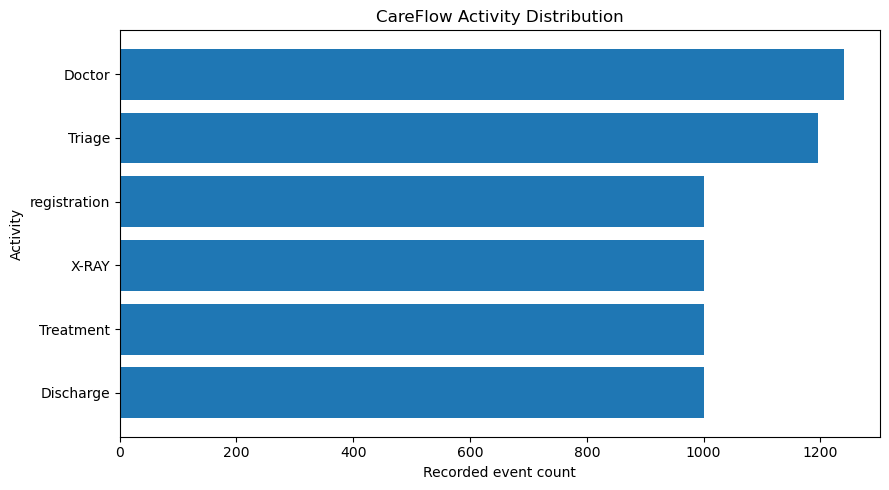

Most frequent activity: Doctor (1,240 events)


In [48]:
activity_counts = df["Activity_Name"].value_counts().rename_axis("Activity_Name").reset_index(name="Event_Count")
display(activity_counts)

plt.figure(figsize=(9, 5))
plt.barh(activity_counts["Activity_Name"], activity_counts["Event_Count"])
plt.title("CareFlow Activity Distribution")
plt.xlabel("Recorded event count")
plt.ylabel("Activity")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

if not activity_counts.empty:
    top = activity_counts.iloc[0]
    print(f"Most frequent activity: {top['Activity_Name']} ({int(top['Event_Count']):,} events)")


## 9. Department analysis (if a Department column exists)

,Department,Event_Count
0,Emergency,5779
1,Trauma,656


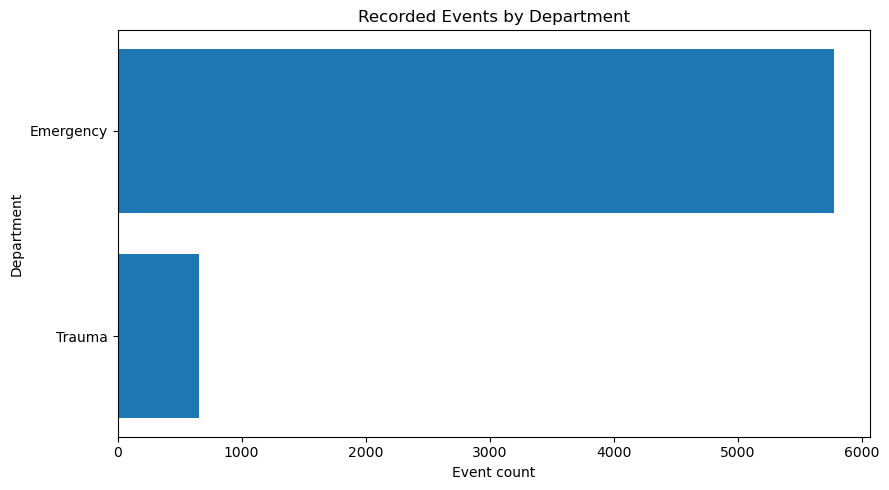

In [49]:
if "Department" in df.columns:
    department_counts = df["Department"].fillna("Unknown").value_counts().rename_axis("Department").reset_index(name="Event_Count")
    display(department_counts)
    plt.figure(figsize=(9, 5))
    plt.barh(department_counts["Department"], department_counts["Event_Count"])
    plt.title("Recorded Events by Department")
    plt.xlabel("Event count")
    plt.ylabel("Department")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    department_counts = pd.DataFrame(columns=["Department", "Event_Count"])
    print("No Department column found; skipping department analysis.")


## 10. Patient activity sequences

In [50]:
activity_sequences = df.groupby("Case_ID")["Activity_Name"].apply(list).reset_index(name="Activity_Sequence")
display(activity_sequences.head(10))

if not activity_sequences.empty:
    example = activity_sequences.iloc[0]
    print("Example case:", example["Case_ID"])
    print("Activity sequence:", " → ".join(example["Activity_Sequence"]))


,Case_ID,Activity_Sequence
0,P0001,"[registration, Triage, Doctor, X-RAY, Treatmen..."
1,P0002,"[registration, Triage, Doctor, X-RAY, Treatmen..."
2,P0003,"[registration, Triage, Doctor, X-RAY, Triage, ..."
3,P0004,"[registration, Triage, Doctor, X-RAY, Treatmen..."
4,P0005,"[registration, Triage, Doctor, X-RAY, Triage, ..."
5,P0006,"[registration, Triage, Doctor, X-RAY, Treatmen..."
6,P0007,"[registration, Triage, Doctor, X-RAY, Triage, ..."
7,P0008,"[registration, Triage, Doctor, X-RAY, Treatmen..."
8,P0009,"[registration, Triage, Doctor, X-RAY, Treatmen..."
9,P0010,"[registration, Triage, Doctor, X-RAY, Triage, ..."


Example case: P0001
Activity sequence: registration → Triage → Doctor → X-RAY → Treatment → Discharge


## 11. Repeated activities / possible loopbacks

In [51]:
df["Repeated_Activity_Flag"] = df.groupby("Case_ID")["Activity_Name"].transform(lambda s: s.duplicated(keep="first"))

patients_with_repeats = int(df.groupby("Case_ID")["Repeated_Activity_Flag"].any().sum())
repeated_event_count = int(df["Repeated_Activity_Flag"].sum())
repeated_patient_percent = round(patients_with_repeats / unique_patients * 100, 2) if unique_patients else 0

repeat_summary = pd.DataFrame({
    "Metric": ["Patients with repeated activity", "Percent of patients", "Repeated activity events"],
    "Value": [patients_with_repeats, repeated_patient_percent, repeated_event_count]
})
display(repeat_summary)
print(f"{patients_with_repeats:,} patients ({repeated_patient_percent}%) had at least one repeated activity.")


,Metric,Value
0,Patients with repeated activity,240.0
1,Percent of patients,24.0
2,Repeated activity events,435.0


240 patients (24.0%) had at least one repeated activity.


## 12. Calculate transition times

In [52]:
df["Next_Activity"] = df.groupby("Case_ID")["Activity_Name"].shift(-1)
df["Next_Timestamp"] = df.groupby("Case_ID")["Timestamp"].shift(-1)
df["Transition_Minutes"] = (df["Next_Timestamp"] - df["Timestamp"]).dt.total_seconds() / 60

all_transitions = df.dropna(subset=["Next_Activity", "Next_Timestamp"]).copy()
negative_transition_count = int((all_transitions["Transition_Minutes"] < 0).sum())
valid_transitions = all_transitions[all_transitions["Transition_Minutes"] >= 0].copy()

transition_summary = (
    valid_transitions.groupby(["Activity_Name", "Next_Activity"], as_index=False)
    .agg(Transition_Count=("Transition_Minutes", "size"),
         Average_Minutes=("Transition_Minutes", "mean"),
         Median_Minutes=("Transition_Minutes", "median"))
    .sort_values("Average_Minutes", ascending=False)
)
transition_summary[["Average_Minutes", "Median_Minutes"]] = transition_summary[["Average_Minutes", "Median_Minutes"]].round(2)

print("Negative transition durations to review:", negative_transition_count)
display(transition_summary.head(10))


Negative transition durations to review: 0


,Activity_Name,Next_Activity,Transition_Count,Average_Minutes,Median_Minutes
1,Doctor,Treatment,195,40.87,41.0
5,X-RAY,Treatment,805,39.71,40.0
6,X-RAY,Triage,195,25.35,25.0
4,Triage,Doctor,1195,22.38,22.0
2,Doctor,X-RAY,1000,20.02,20.0
3,Treatment,Discharge,1000,19.83,20.0
7,registration,Triage,1000,14.02,14.0
0,Doctor,Doctor,45,12.69,13.0


## 13. Visualize the longest transitions

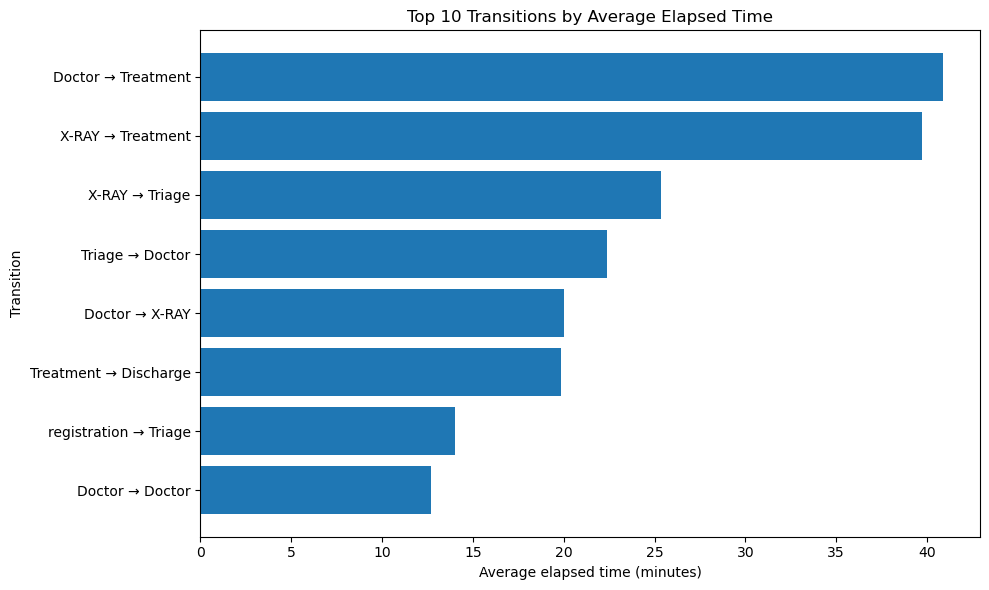

In [53]:
if not transition_summary.empty:
    top_transitions = transition_summary.head(10).copy()
    top_transitions["Transition"] = top_transitions["Activity_Name"] + " → " + top_transitions["Next_Activity"]
    plt.figure(figsize=(10, 6))
    plt.barh(top_transitions["Transition"], top_transitions["Average_Minutes"])
    plt.title("Top 10 Transitions by Average Elapsed Time")
    plt.xlabel("Average elapsed time (minutes)")
    plt.ylabel("Transition")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No valid consecutive transitions found.")


## 14. Event volume over time

,Event_Date,Event_Count
0,2026-09-01,163
1,2026-09-02,285
2,2026-09-03,236
3,2026-09-04,227
4,2026-09-05,230
5,2026-09-06,232
6,2026-09-07,179
7,2026-09-08,187
8,2026-09-09,270
9,2026-09-10,235


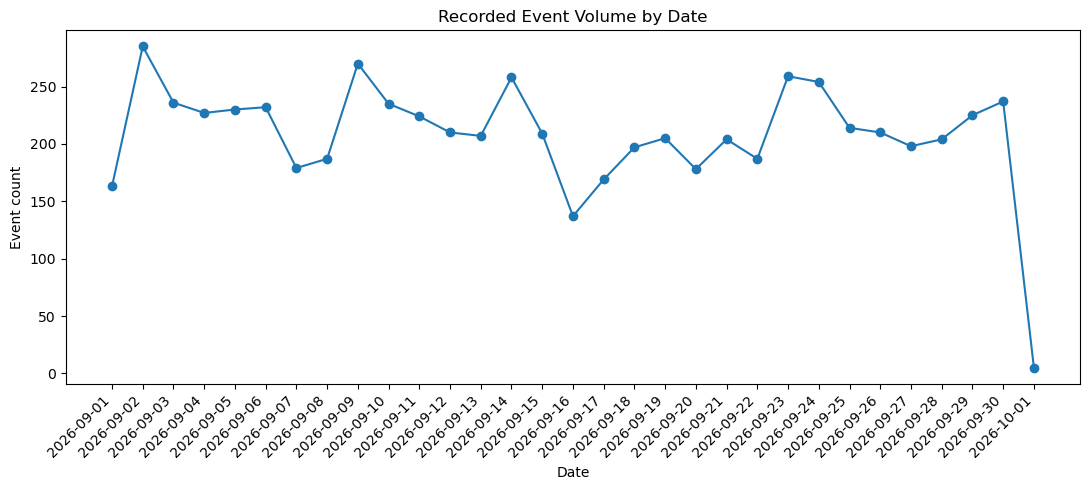

In [54]:
daily_events = df.assign(Event_Date=df["Timestamp"].dt.date).groupby("Event_Date").size().reset_index(name="Event_Count")
display(daily_events.head(10))

plt.figure(figsize=(11, 5))
plt.plot(daily_events["Event_Date"].astype(str), daily_events["Event_Count"], marker="o")
plt.title("Recorded Event Volume by Date")
plt.xlabel("Date")
plt.ylabel("Event count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 15. Automatically generated business insights

In [55]:
print("CAREFLOW — EDA BUSINESS INSIGHTS")
print("=" * 38)
print(f"Cleaned dataset: {unique_patients:,} patient cases, {total_events:,} event records, {unique_activities} activity types.")
print(f"Rows removed during cleaning: {rows_before - rows_after:,}.")

if not activity_counts.empty:
    top = activity_counts.iloc[0]
    print(f"Most frequently recorded activity: {top['Activity_Name']} ({int(top['Event_Count']):,} events).")

if not transition_summary.empty:
    slow = transition_summary.iloc[0]
    print(f"Highest average elapsed transition: {slow['Activity_Name']} → {slow['Next_Activity']}: "
          f"{slow['Average_Minutes']} minutes average; median {slow['Median_Minutes']} minutes; "
          f"{int(slow['Transition_Count'])} observations.")

print(f"Patients with repeated activities: {patients_with_repeats:,} ({repeated_patient_percent}%).")
print("Recommendation: investigate long transitions and repeated journeys with operational context.")
print("Limitation: synthetic practice data; elapsed time is not necessarily actual waiting time.")


CAREFLOW — EDA BUSINESS INSIGHTS
Cleaned dataset: 1,000 patient cases, 6,435 event records, 6 activity types.
Rows removed during cleaning: 8.
Most frequently recorded activity: Doctor (1,240 events).
Highest average elapsed transition: Doctor → Treatment: 40.87 minutes average; median 41.0 minutes; 195 observations.
Patients with repeated activities: 240 (24.0%).
Recommendation: investigate long transitions and repeated journeys with operational context.
Limitation: synthetic practice data; elapsed time is not necessarily actual waiting time.


## 16. Export outputs for SQL, Excel, and Power BI

In [56]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "careflow_cleaned_event_log.csv": df,
    "careflow_kpi_summary.csv": kpi_summary,
    "careflow_activity_counts.csv": activity_counts,
    "careflow_transition_summary.csv": transition_summary,
    "careflow_repeated_activity_summary.csv": repeat_summary,
    "careflow_daily_events.csv": daily_events
}
if not department_counts.empty:
    exports["careflow_department_counts.csv"] = department_counts

for filename, table in exports.items():
    table.to_csv(output_dir / filename, index=False)
    print("Saved:", (output_dir / filename).resolve())

print("Export complete.")


Saved: C:\Users\hp\outputs\careflow_cleaned_event_log.csv
Saved: C:\Users\hp\outputs\careflow_kpi_summary.csv
Saved: C:\Users\hp\outputs\careflow_activity_counts.csv
Saved: C:\Users\hp\outputs\careflow_transition_summary.csv
Saved: C:\Users\hp\outputs\careflow_repeated_activity_summary.csv
Saved: C:\Users\hp\outputs\careflow_daily_events.csv
Saved: C:\Users\hp\outputs\careflow_department_counts.csv
Export complete.


# Conclusion-
### 1. Dataset Overview
The cleaned CareFlow dataset contains **1,000 unique patient cases and 6,435 event records** across 6 activity types. Python and pandas were used to explore hospital activity patterns, patient journeys, and transition times.

### 2. Data Quality
During data cleaning, **8 rows were removed** because of missing or invalid required fields or exact duplication. This helped prepare the dataset for further analysis.

### 3. Most Frequent Activity
**Doctor** was the most frequently recorded activity, with **1,240 events**. This indicates that Doctor-related events occur frequently in the dataset, but the event count alone does not prove that this stage is inefficient.

### 4. Transition with the Highest Average Elapsed Time
The **Doctor → Treatment** transition had the highest average elapsed time among the observed transitions:

- Average elapsed time: **40.87 minutes**
- Median elapsed time: **41 minutes**
- Number of observations: **195**

This transition is a potential area for further investigation. Additional information is needed to determine whether the elapsed time represents waiting, planned care, or gaps in event recording.

### 5. Repeated Activities
A total of **240 patients, representing 24% of all patient cases**, had at least one activity that repeated later in their recorded journey. These patterns may indicate process loops or rework, but repeated activities may also be clinically appropriate.

### 6. Business Recommendations
- Investigate the Doctor-to-Treatment transition to understand why it has a relatively high average elapsed time.
- Review repeated patient journeys to distinguish necessary activities from potentially avoidable repetition.
- Validate event timestamps and activity definitions before making operational decisions.
- Establish baseline KPIs and compare them with future results before claiming an improvement.

### 7. Limitations
The dataset contains synthetic practice data and does not represent actual hospital performance. The elapsed time between recorded activities is not necessarily actual waiting time. Repeated activities do not automatically indicate errors or inefficiency.

### Overall Conclusion
The analysis identified Doctor as the most frequently recorded activity and the Doctor-to-Treatment transition as a potential area for investigation. It also found repeated activities in 24% of patient cases. These findings demonstrate how Python-based exploratory data analysis can help identify patterns and generate business questions. However, further validation with real operational data would be necessary before recommending changes to hospital processes.

# CareFlow Project — Process Mining Using PM4Py

## Step 1: Installing and Importing Required Libraries

In [57]:
%pip install pm4py

Note: you may need to restart the kernel to use updated packages.


In [58]:
import pm4py 
import importlib.metadata
import pandas as pd
import matplotlib.pyplot as plt


print('PM4PY Version:',importlib.metadata.version("pm4py"))
print("PM4PY Installation Successful")

PM4PY Version: 2.7.23.10
PM4PY Installation Successful


## Step 2: Loading the CareFlow Event Log Dataset

In [59]:
df  = pd.read_csv("careflow_raw_event_log.csv")

print("Total_records:",len(df))
print("Total Columns:",df.columns.tolist())
print("Shape:",df.shape)
display(df.head())


Total_records: 6443
Total Columns: ['Case_ID', 'Activity_Name', 'Timestamp', 'Patient_Age', 'Gender', 'Department', 'Doctor_ID', 'Pathway_Type', 'Event_Reason']
Shape: (6443, 9)


,Case_ID,Activity_Name,Timestamp,Patient_Age,Gender,Department,Doctor_ID,Pathway_Type,Event_Reason
0,P0001,registration,2026-09-03 16:21:00,70,Male,Emergency,D02,Normal,NaN
1,P0001,Triage,2026-09-03 16:29:00,70,Male,Emergency,D02,Normal,NaN
2,P0001,Doctor,2026-09-03 16:57:00,70,Male,Emergency,D02,Normal,NaN
3,P0001,X-RAY,2026-09-03 17:16:00,70,Male,Emergency,D02,Normal,NaN
4,P0001,Treatment,2026-09-03 18:07:00,70,Male,Emergency,D02,Normal,NaN


## Step 3: Data Quality Assessment and Cleaning

In [60]:
# FInd Missing Columns
required_columns = ['Case_ID','Activity_Name','Timestamp']
missing_columns = [
    col for col in required_columns
    if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"Required Columns Missing: {required_columns}"
    )

events = df[required_columns].copy()
events['Timestamp'] = pd.to_datetime(events['Timestamp'], errors = 'coerce')

print("Missing Values Before Cleaning")

Missing Values Before Cleaning


## Step 4: Converting Data into PM4Py Event Log Format

In [61]:
# Rename Columns
event_log_df = events.rename(
    columns = {
        "Case_ID":"case:concept:name",
        "Activity_Name":"concept:name",
        "Timestamp":"time:timestamp"})

# Format for PM4PY
event_log_df = pm4py.format_dataframe(
           event_log_df,
           case_id = "case:concept:name",
           activity_key = "concept:name",
           timestamp_key = "time:timestamp")

# Confirmation
print("Event Log Prepared Successfully")

display(event_log_df[
        ["case:concept:name",
         "concept:name",
         "time:timestamp"]].head())

Event Log Prepared Successfully


,case:concept:name,concept:name,time:timestamp
0,P0001,registration,2026-09-03 16:21:00+00:00
1,P0001,Triage,2026-09-03 16:29:00+00:00
2,P0001,Doctor,2026-09-03 16:57:00+00:00
3,P0001,X-RAY,2026-09-03 17:16:00+00:00
4,P0001,Treatment,2026-09-03 18:07:00+00:00


## 5. Discovering Patient Activity Transitions Using Directly-Follows Graph (DFG)


In [62]:
dfg,start_activities,end_activities = pm4py.discover_dfg(event_log_df)
print("Start activities:")
print(start_activities)

print("\nEnd activities:")
print(end_activities)

print("\nActivity Transitions:")

for (source, target), count in sorted(
    dfg.items(),
    key = lambda item: item[1],
    reverse =True):
    print(f"{source}->{target}:{count}")

Start activities:
{'registration': 1000}

End activities:
{'Discharge': 1000}

Activity Transitions:
Triage->Doctor:1195
Doctor->X-RAY:1000
Treatment->Discharge:1000
registration->Triage:1000
X-RAY->Treatment:805
Doctor->Treatment:195
X-RAY->Triage:195
Doctor->Doctor:47
Discharge->Discharge:2
Triage->Triage:2
Treatment->Treatment:1
X-RAY->X-RAY:1


## Step 6: Visualizing the Patient Process Map

In [63]:
from pm4py.visualization.dfg import visualizer as dfg_visualizer
from IPython.display import Image,display

In [64]:
%pip install networkx

Note: you may need to restart the kernel to use updated packages.


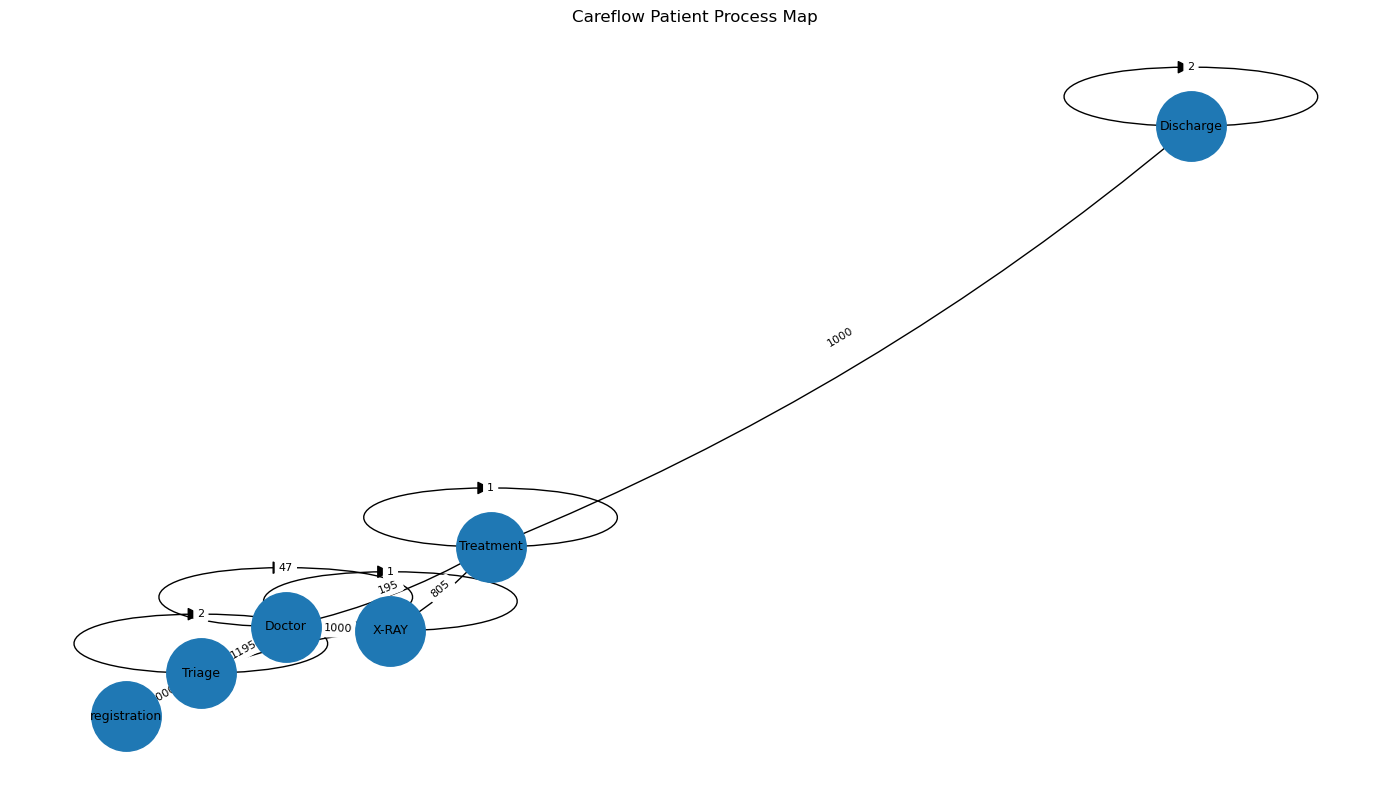

In [65]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a directed graph from the PM4Py DFG
G = nx.DiGraph()

# Add edges from DFG
for (source,target),count in dfg.items():
    G.add_edge(source,target,weight = count)

# Set layout for nodes
plt.figure(figsize = (14,8))
pos = nx.spring_layout(G,seed = 42)

# Draw Nodes and labels
nx.draw_networkx_nodes(G,pos,node_size=2500)
nx.draw_networkx_labels(G,pos,font_size = 9)

# Draw Arrows between Activities
nx.draw_networkx_edges(G, pos,arrows = True,arrowsize = 20,
                       connectionstyle = "arc3, rad= 0.08")

# Draw edges Label(Counts)
edge_labels = nx.get_edge_attributes(G,"weight")
nx.draw_networkx_edge_labels(G,pos,edge_labels= edge_labels, font_size= 8)

# Plot the Graph
plt.title("Careflow Patient Process Map")
plt.axis("off")
plt.tight_layout()

# Save and show
plt.savefig(
    "careflow_process_map.png",
    dpi= 150,
    bbox_inches = "tight")
plt.show()


## Conclusion:The process map shows that almost all patients follow a clear path: Registration → Triage → Doctor → Treatment → Discharge, with only a smaller branch going through X-RAY. The edge labels highlight frequencies, confirming that the main flow is consistent and loops (like repeated doctor visits or treatments) are rare

## Step 7: Identifying Common Patient Pathways (Process Variants)

### Objective
To identify the most common sequences of activities followed by patients and understand variations in patient journeys.

In [66]:
# Discover different patient journey variants
variants = pm4py.get_variants_as_tuples(event_log_df)

# Create a summary of patient pathways
variant_rows= []

for activities, case_ids in variants.items():
    variant_rows.append({
        "Patient_Pathway":"->".join(map(str,activities)),
        "Number of Patients":case_ids
    })
variant_summary = pd.DataFrame(variant_rows)

# Sort pathways by patient count
variant_sumary = variant_summary.sort_values(
    by = "Number of Patients",
    ascending = False
).reset_index(drop=True)

# Display Top 10 Pathways
print("Top 10 Most Common Patient Pathways:")
display(variant_summary.head(10))


Top 10 Most Common Patient Pathways:


,Patient_Pathway,Number of Patients
0,registration->Triage->Doctor->X-RAY->Treatment...,754
1,registration->Triage->Doctor->X-RAY->Triage->D...,193
2,registration->Triage->Doctor->X-RAY->Triage->D...,1
3,registration->Triage->Doctor->Doctor->X-RAY->T...,46
4,registration->Triage->Doctor->X-RAY->Treatment...,2
5,registration->Triage->Doctor->X-RAY->Treatment...,1
6,registration->Triage->Triage->Doctor->X-RAY->T...,2
7,registration->Triage->Doctor->X-RAY->X-RAY->Tr...,1


In [67]:
# To save file in CSV Format
variant_summary.to_csv(
    "careflow_process_variants.csv",
    index= False)
print("Patient Pathway Summary Exported Successfully")

Patient Pathway Summary Exported Successfully


## Step 8: Generating Activity and Transition Summary Tables

### Objective
To summarize activity frequency, the number of unique patients involved in each activity, and the frequency of transitions between consecutive activities.

In [68]:
# Create Activity level Summary
activity_summary = (
    events.groupby("Activity_Name")
    .agg(
        total_events = ("Activity_Name","size"),
        Unique_Patients = ("Case_ID","nunique"))
    .reset_index()
    .sort_values("total_events",ascending= False)
                   )
# Display Activity Summary
print("Activity Summary:")
print(activity_summary)                   
                    

Activity Summary:
  Activity_Name  total_events  Unique_Patients
1        Doctor          1242             1000
3        Triage          1197             1000
0     Discharge          1002             1000
2     Treatment          1001             1000
4         X-RAY          1001             1000
5  registration          1000             1000


In [72]:
# Create transition-level summary from the PM4Py DFG
transition_summary = pd.DataFrame([
    {"current_activity": source,
     "next_activity":target,
     "transition_count":count
    }
    for (source,target),count in dfg.items()
])
# Sort by the most frequent transitions
transiton_summary = transition_summary.sort_values(
    by = "transition_count",ascending = False
).reset_index(drop= True)

# Display Top 10 transitions
print("Top 10 Activity Transitions:\n")
print(transition_summary.head(10))

Top 10 Activity Transitions:

  current_activity next_activity  transition_count
0        Discharge     Discharge                 2
1           Doctor        Doctor                47
2           Doctor     Treatment               195
3           Doctor         X-RAY              1000
4        Treatment     Discharge              1000
5        Treatment     Treatment                 1
6           Triage        Doctor              1195
7           Triage        Triage                 2
8            X-RAY     Treatment               805
9            X-RAY        Triage               195


In [74]:
# Export Sumary Files to CSV.

# Export Activity Summary
activity_summary.to_csv(
    "careflow_pm4py_activity_summary.csv",index= False)

# Export Transition summary
transition_summary.to_csv(
    "careflow_pm4py_transition_summary.csv",index= False)

print("Activity and Transition summary files exported successfully!")

Activity and Transition summary files exported successfully!


In [76]:
# Verify Output
from pathlib import Path

for filename in [
    "careflow_pm4py_activity_summary.csv",
    "careflow_pm4py_transition_summary.csv"
]:
    print(filename, ":", Path(filename).exists())

careflow_pm4py_activity_summary.csv : True
careflow_pm4py_transition_summary.csv : True


## Step 8: Visualizing the Top 10 Activity Transitions

### Objective
To visualize the ten most frequent transitions between consecutive patient activities and understand common patterns in the CareFlow process.4

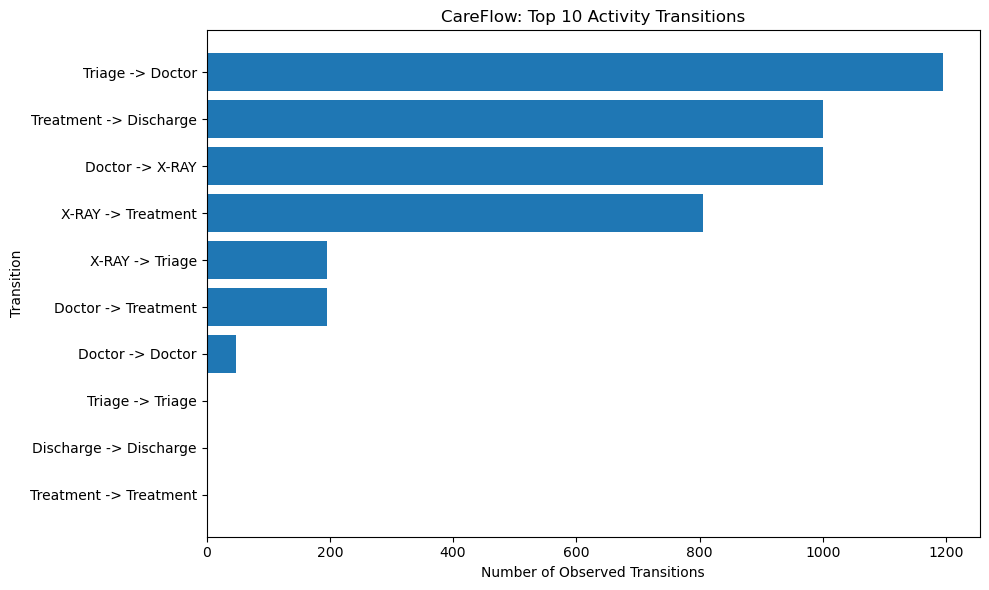

Top 10 activity transitions chart created successfully!


In [84]:
# Select the top 10 most frequent transitions
top_transitions = transition_summary.head(10).copy()

# Combine current and next activity into one Label
top_transitions["transition"] = (
    top_transitions["current_activity"]
    + " -> "
    + top_transitions["next_activity"]
)

# Sort for readable horizontal bar chart
top_transitions = top_transitions.sort_values("transition_count", ascending=True)

# Create the chart
plt.figure(figsize=(10,6))
labels = top_transitions["transition"]

# FIX: use transition_count instead of transitions
plt.barh(
    labels,
    top_transitions["transition_count"]
)

plt.title("CareFlow: Top 10 Activity Transitions")
plt.xlabel("Number of Observed Transitions")
plt.ylabel("Transition")
plt.tight_layout()

# Save the chart
plt.savefig(
    "careflow_top_transitions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Top 10 activity transitions chart created successfully!")


## Step 10: Final Verification of Process Mining Outputs

### Objective
To verify that all expected process mining visualizations and summary files have been generated successfully.

In [87]:

from pathlib import Path

# List of expected output files
output_files = [
    "careflow_process_map.png",
    "careflow_process_variants.csv",
    "careflow_pm4py_activity_summary.csv",
    "careflow_pm4py_transition_summary.csv",
    "careflow_top_transitions.png"
]

# Verify file existence
print("CareFlow Process Mining Output Verification")
print("-" * 50)

for filename in output_files:
    path = Path(filename)

    if path.exists():
        print(f"SUCCESS: {filename}")
    else:
        print(f"MISSING: {filename}")

print("-" * 50)
print("Verification completed!")


CareFlow Process Mining Output Verification
--------------------------------------------------
SUCCESS: careflow_process_map.png
SUCCESS: careflow_process_variants.csv
SUCCESS: careflow_pm4py_activity_summary.csv
SUCCESS: careflow_pm4py_transition_summary.csv
SUCCESS: careflow_top_transitions.png
--------------------------------------------------
Verification completed!
